In [2]:
from pathlib import Path

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "raw" / "train.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/raw/train.csv from the current directory")

RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"

In [3]:
import pandas as pd

df_train = pd.read_csv(RAW / "train.csv")
df_test = pd.read_csv(RAW / "test.csv")

required_columns = {"prompt", "essay", "evaluation", "band"}
for split_name, frame in (("train", df_train), ("test", df_test)):
    missing_columns = required_columns.difference(frame.columns)
    if missing_columns:
        raise ValueError(f"{split_name} data is missing required columns: {sorted(missing_columns)}")

all_data = pd.concat(
    [df_train.assign(split="train"), df_test.assign(split="test")],
    
    ignore_index=True,
)
all_data_source = all_data.copy()
print(f"Train rows: {len(df_train):,}; test rows: {len(df_test):,}; combined: {len(all_data):,}")
all_data.head()

Train rows: 9,833; test rows: 491; combined: 10,324


,Unnamed: 0,prompt,essay,evaluation,band,split
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train


In [4]:
#Kiểm tra missing data

print("Rows by split:")
print(all_data["split"].value_counts().reindex(["train", "test"]))

print("\nMissing values by column:")
display(all_data.isna().sum().to_frame("missing"))

print("Exact duplicate rows (excluding the split marker):")
print(all_data.drop(columns="split").duplicated().sum())

print("Repeated essay rows:")
print(all_data["essay"].duplicated().sum())

print("\nBlank or whitespace-only strings by text column:")
for column in all_data.select_dtypes(include=["object", "string"]).columns:
    blank_count = all_data[column].astype("string").str.strip().eq("").fillna(False).sum()
    print(f"{column}: {blank_count}")

Rows by split:
split
train    9833
test      491
Name: count, dtype: int64

Missing values by column:


,missing
Unnamed: 0,0
prompt,0
essay,0
evaluation,0
band,0
split,0


Exact duplicate rows (excluding the split marker):
0
Repeated essay rows:
1339

Blank or whitespace-only strings by text column:
prompt: 0
essay: 0
evaluation: 0
band: 0
split: 0


In [5]:
#Kiểm tra các bài luận trùng có bị gán nhiều mức điểm khác nhau không
duplicate_check = (
    all_data.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
    .sort_values("so_ban_ghi", ascending=False)
)

print("Số nhóm bài luận trùng:", len(duplicate_check))

print(
    "Số nhóm có nhiều mức điểm:",
    (duplicate_check["so_band_khac_nhau"] > 1).sum()
)
duplicate_check

Số nhóm bài luận trùng: 1217
Số nhóm có nhiều mức điểm: 477


,essay,so_ban_ghi,so_band_khac_nhau
758,"Over the past decades, environmental problems ...",7,1
1079,There is an opinion that employers should not ...,5,4
482,It is inevitable for prominent people to have ...,4,2
274,"In some countries, famous individuals often fe...",4,2
261,"In recent years, the increasing population has...",4,2
...,...,...,...
1196,"Without any ,doubt society is divided into two...",2,1
1197,few people are of the opinion that robots are ...,2,2
1198,globalization and the flourishing of multinati...,2,1
1199,having the opportunity to work at a young age ...,2,1


In [6]:
conflicting_essays = duplicate_check[
    duplicate_check["so_band_khac_nhau"] > 1
]["essay"]

if conflicting_essays.empty:
    print("No repeated essays have conflicting band labels.")
else:
    sample_essay = conflicting_essays.iloc[0]
    display(
        all_data.loc[
            all_data["essay"] == sample_essay,
            ["split", "prompt", "essay", "band", "evaluation"],
        ]
    )

,split,prompt,essay,band,evaluation
2618,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6\r\r\r\r\r\r\r\r,**Task Achievement:**\n\nThe candidate has eff...
2624,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r\r\r\r,### Task Achievement:\n- The candidate has eff...
3022,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6\r\r\r\r\r,## Task Achievement:\n- The candidate effectiv...
3028,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r,**Task Achievement:**\n\n- The essay effective...
9972,test,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r,**Task Achievement:**\n\n- The essay effective...


In [7]:
#Chuẩn hóa band để so sánh chính xác
# Tạo cột điểm dạng số để kiểm tra, không sửa dữ liệu gốc
all_data_check = all_data.copy()

band_text = (
    all_data_check["band"].astype("string")
    .str.replace(r"[\r\n\t]+", "", regex=True)
    .str.strip()
)
all_data_check["band_num"] = pd.to_numeric(
    band_text,
    errors="coerce"
)
all_data_check["band_comparison"] = all_data_check["band_num"].astype("string").fillna(band_text)

duplicate_check_num = (
    all_data_check.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band_comparison", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print(
    "Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa:",
    (duplicate_check_num["so_band_khac_nhau"] > 1).sum()
)

print(
    "Số nhãn band không hợp lệ (không tính nhãn đặc biệt '<4'):",
    (all_data_check["band_num"].isna() & band_text.ne("<4")).sum()
)
print("Số nhãn '<4':", band_text.eq("<4").sum())
all_data_check.loc[
    all_data_check["band_num"].isna() & band_text.ne("<4"),
    ["split", "band"],
].drop_duplicates()
all_data

Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa: 5
Số nhãn band không hợp lệ (không tính nhãn đặc biệt '<4'): 0
Số nhãn '<4': 612


,Unnamed: 0,prompt,essay,evaluation,band,split
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
...,...,...,...,...,...,...
10319,486,"As well as making money, businesses also have ...",The role of companies is to produce all the go...,**Task Achievement:** 6\n\nThe essay effective...,6,test
10320,487,"As well as making money, businesses also have ...",Although earning money is one of the most impo...,**Task Achievement:**\n\n- The essay adequatel...,7.5,test
10321,488,"As well as making money, businesses also have ...",IIt is argued by many people that companies ha...,**Task Achievement: 4**\n\nThe essay addresses...,5,test
10322,489,"As well as making money, businesses also have ...","In this modern era , everyone needs money for ...",## Task Achievement:\n- The candidate has adeq...,4,test


In [24]:
# all_data = remaining_data
#Kiểm tra toàn bộ các dạng nhãn band
# Chuẩn hóa ký tự xuống dòng và khoảng trắng
band_cleaned = (
    all_data["band"]
    .astype(str)
    .str.replace(r"[\r\n\t]+", "", regex=True)
    .str.strip()
)

print("Các nhãn band sau khi loại ký tự thừa:")
display(band_cleaned.value_counts().to_frame("Số lượng"))

print("\nSố nhãn bắt đầu bằng '<':",
      band_cleaned.str.startswith("<").sum())

print("\nSố nhãn còn lại không phải số:",
      pd.to_numeric(band_cleaned, errors="coerce").isna().sum())


Các nhãn band sau khi loại ký tự thừa:


,Số lượng
band,
7,1356
6.5,1168
6,1143
7.5,1105
5,1046
5.5,954
8,699
4.5,646
4,594



Số nhãn bắt đầu bằng '<': 574

Số nhãn còn lại không phải số: 574


In [25]:
#Chuẩn hóa nhãn band cho all data
import pandas as pd
def clean_band(series):
    return (
        series.astype(str)
        .str.replace(r"[\r\n\t]+", "", regex=True)
        .str.strip()
    )

all_data.loc[:,"band_clean"] = clean_band(all_data.loc[:,"band"])
# test["band_clean"] = clean_band(test["band"])

print("Phân bố nhãn band trong all_data:")
display(all_data["band_clean"].value_counts().sort_index().to_frame("Số lượng"))
all_data
# print("\nPhân bố nhãn band trong test:")
# display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

Phân bố nhãn band trong all_data:


,Số lượng
band_clean,
4,594
4.5,646
5,1046
5.0,1
5.5,954
6,1143
6.5,1168
7,1356
7.5,1105


,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,Task Achievement: 7\nThe essay effectively add...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,7.5,Interviews form the basic criteria for most la...
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,Task Achievement: 5.0\n- The candidate has eff...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.0,Interviews form the basic selecting criteria f...
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,Task Achievement:\n- The candidate has effecti...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interview form the basic selection criteria fo...
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,Task Achievement:\n- The candidate has adequat...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interviews form the basic selection criteria f...
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,Task Achievement:\n\nThe essay adequately addr...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,4,Interviews from the basic selecting criteria f...
...,...,...,...,...,...,...,...,...
9828,9828,Nations should spend more money on skills and ...,"These days, many countries use a huge amount o...",Task Achievement:\nThe essay addresses the tas...,8,train,8,Nations should spend more money on skills and ...
9829,9829,Nations should spend more money on skills and ...,Skills are required in order to achieve succes...,Task Achievement:\n- The candidate has not eff...,<4,train,<4,Nations should spend more money on skills and ...
9830,9830,Nations should spend more money on skills and ...,There is a contradictory view among the people...,Task Achievement:\n- The essay adequately addr...,7,train,7,Nations should spend more money on skills and ...
9831,9831,Nations should spend more money on skills and ...,Many today feel that countries should prioriti...,Task Achievement:\n- The candidate has effecti...,7.5,train,7.5,Nations should spend more money on skills and ...


In [10]:
#Chuẩn hóa định dạng nhãn điểm
def normalize_band(series):
    cleaned = clean_band(series)

    def normalize_one(value):
        if value == "<4":
            return "<4"

        try:
            number = float(value)
            return str(float(number)) if number.is_integer() else str(number)
        except ValueError:
            return value

    return cleaned.apply(normalize_one)


all_data.loc[:,"band_clean"] = normalize_band(all_data.loc[:,"band"])

print("Phân bố nhãn all_data sau chuẩn hóa:")
display(all_data.loc[:,"band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nTổng số mẫu all_data:", len(all_data))

Phân bố nhãn all_data sau chuẩn hóa:


,Số lượng
band_clean,
4.0,627
4.5,676
5.0,1084
5.5,1013
6.0,1201
6.5,1235
7.0,1434
7.5,1146
8.0,735



Tổng số mẫu all_data: 10324


In [11]:
#chuẩn hóa, loại bỏ những ký tự thừa ở essay và evaluation
import re
import unicodedata

def clean_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""

    # 1. Chuẩn hóa Unicode (NFKC) & đồng nhất dấu nháy/gạch ngang
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r"[’‘`]", "'", text)        # Chuyển smart apostrophe về nháy đơn chuẩn
    text = re.sub(r"[“”]", '"', text)        # Chuyển smart quotes về nháy đôi chuẩn
    text = re.sub(r"[—–]", "-", text)         # Đồng nhất các loại dấu gạch ngang (em-dash, en-dash)

    # 2. Xóa các ký tự không hợp lệ (emoji, ký hiệu toán học lạ,...)
    # Giữ lại: chữ cái, số, khoảng trắng, các dấu câu cơ bản: . , ? ! : ; ' " - ( ) % $
    text = re.sub(r"[^\w\s\.,?!\x27\"\-:;()%\$]", "", text)

    # 3. Sửa lỗi khoảng trắng quanh dấu câu
    # 3a. Xóa khoảng trắng thừa TRƯỚC dấu câu (ví dụ: "good ." -> "good.")
    text = re.sub(r"\s+([.,?!:;])", r"\1", text)
    
    # 3b. Thêm khoảng trắng SAU dấu câu nếu dính liền với chữ cái (ví dụ: "however,some" -> "however, some")
    text = re.sub(r"([.,?!:;])([A-Za-z])", r"\1 \2", text)
    
    # 3c. Xử lý khoảng trắng thừa quanh dấu ngoặc đơn
    text = re.sub(r"\(\s+", "(", text)
    text = re.sub(r"\s+\)", ")", text)

    # 4. Chuẩn hóa dòng và khoảng trắng (Whitespace cleanup)
    text = re.sub(r"[\t\r]", " ", text)        # Chuyển tab và \r thành khoảng trắng
    text = re.sub(r"[ ]{2,}", " ", text)       # Thu gọn nhiều khoảng trắng liên tiếp trên cùng 1 dòng
    text = re.sub(r" *\n *", "\n", text)       # Xóa khoảng trắng thừa ở đầu/cuối mỗi dòng
    text = re.sub(r"\n{3,}", "\n\n", text)     # Thu gọn 3+ dòng trống liên tiếp thành 2 dòng (phân chia đoạn văn)

    return text.strip()
all_data_copy = all_data.copy()
#loại bỏ những bài có essay, evaluation giống nhau
all_data_copy["prompt_clean"] = all_data_copy["prompt"].map(clean_text)
all_data_copy[["essay", "evaluation"]] = all_data_copy[["essay", "evaluation"]].map(clean_text)

remaining_data = all_data_copy.drop_duplicates(
    subset=["prompt_clean", "essay", "evaluation"], keep="first"
)
print(f"Trước khi xóa: {len(all_data_copy)}")
print(f'Sau khi xóa {len(remaining_data)}')
print(f'Số dòng bị loại: {len(all_data_copy) - len(remaining_data)}')
print(f'Tỉ lệ bị loại: {(len(all_data_copy) - len(remaining_data)) / len(all_data_copy):.2%}')

Trước khi xóa: 10324
Sau khi xóa 9833
Số dòng bị loại: 491
Tỉ lệ bị loại: 4.76%


In [12]:
#những bài giống nhau nhưng nhiều band điểm khác nhau
# tính khoảng cách giữa điểm lớn nhất và điểm nhỏ nhất, <= 1.0 -> lấy trung bình, > 1.0 -> bỏ do độ lệch quá lớn
# update điểm vào dataframe gốc
import numpy as np
import math

all_data = remaining_data

def round_ielts(score):
    if pd.isna(score):
        return score
    
    frac, integral = math.modf(score)
    if frac < 0.25:
        return integral + 0.0
    elif frac < 0.75:
        return integral + 0.5
    else:
        return integral + 1.0
essay_diff_scores = all_data.groupby('essay').agg(
    unique_score_count=('band_clean', 'nunique'),
    all_scores=('band_clean', lambda x: list(x.unique()))
).reset_index()
essay_diff_scores = essay_diff_scores[essay_diff_scores['unique_score_count'] > 1]
# print(type(essay_diff_scores.loc[:,'all_scores']))
for idx, row in essay_diff_scores.iterrows():
    if ('<4' in row['all_scores']):
        continue
    scores = np.array(row['all_scores']).astype(float)
    
    if len(scores) == 2:
        distance = np.max(scores) - np.min(scores)
        if (distance <= 1.0):
            essay_diff_scores.at[idx,'all_scores'] = round_ielts(np.mean(scores))
        else:
            essay_diff_scores.at[idx,'all_scores'] = np.nan
    else:
        essay_diff_scores.at[idx,'all_scores'] = np.median(scores)

essay_diff_scores_copy = essay_diff_scores.copy()
has_less_than_score = essay_diff_scores_copy["all_scores"].map(
    lambda scores: isinstance(scores, list)
    and any("<" in str(score) for score in scores)
)
essay_diff_scores_copy["band_clean"] = essay_diff_scores_copy["all_scores"].map(
    lambda score: (
        pd.NA if isinstance(score, list) or pd.isna(score)
        else str(int(score)) if float(score).is_integer()
        else str(float(score))
    )
)
# essay_diff_scores.loc[has_less_than_score, "band_clean"] = pd.NA
score_lookup = essay_diff_scores_copy.loc[~has_less_than_score].set_index("essay")["band_clean"]
update_mask = all_data["essay"].isin(score_lookup.index)
all_data.loc[update_mask, "band_clean"] = all_data.loc[update_mask, "essay"].map(score_lookup)

preserved_essay_count = int(has_less_than_score.sum())
preserved_essay_label = "essay" if preserved_essay_count == 1 else "essays"
print(
    f"Updated band_clean for {int(update_mask.sum())} rows across "
    f"{len(score_lookup):,} essays; preserved {preserved_essay_count} "
    f"{preserved_essay_label} with a '<' score label."
)
all_data = all_data.dropna()
all_data = all_data.drop_duplicates(subset=['essay', 'evaluation', 'band_clean'])
print('Sau khi loại bỏ trùng lặp ở essay, evaluation và band_clean:')
all_data

Updated band_clean for 12 rows across 5 essays; preserved 1 essay with a '<' score label.
Sau khi loại bỏ trùng lặp ở essay, evaluation và band_clean:


,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,Task Achievement: 7\nThe essay effectively add...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,7.5,Interviews form the basic criteria for most la...
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,Task Achievement: 5.0\n- The candidate has eff...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.0,Interviews form the basic selecting criteria f...
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,Task Achievement:\n- The candidate has effecti...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interview form the basic selection criteria fo...
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,Task Achievement:\n- The candidate has adequat...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interviews form the basic selection criteria f...
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,Task Achievement:\n\nThe essay adequately addr...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,4.0,Interviews from the basic selecting criteria f...
...,...,...,...,...,...,...,...,...
9828,9828,Nations should spend more money on skills and ...,"These days, many countries use a huge amount o...",Task Achievement:\nThe essay addresses the tas...,8,train,8.0,Nations should spend more money on skills and ...
9829,9829,Nations should spend more money on skills and ...,Skills are required in order to achieve succes...,Task Achievement:\n- The candidate has not eff...,<4,train,<4,Nations should spend more money on skills and ...
9830,9830,Nations should spend more money on skills and ...,There is a contradictory view among the people...,Task Achievement:\n- The essay adequately addr...,7,train,7.0,Nations should spend more money on skills and ...
9831,9831,Nations should spend more money on skills and ...,Many today feel that countries should prioriti...,Task Achievement:\n- The candidate has effecti...,7.5,train,7.5,Nations should spend more money on skills and ...


Thống kê độ dài bài luận (số từ):


,count,mean,std,min,25%,50%,75%,max
word_count,9826.0,293.031956,57.922542,50.0,263.0,289.0,322.0,1557.0


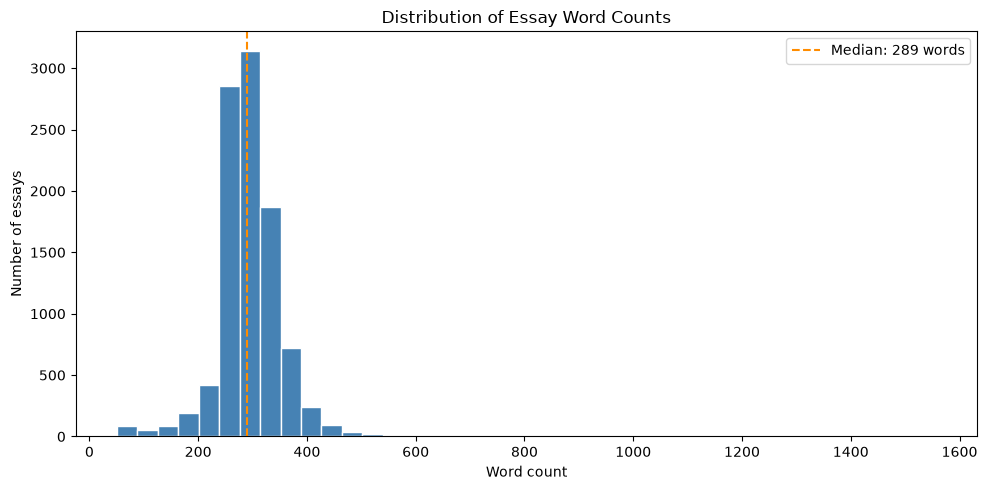


5 bài luận ngắn nhất:


,essay,word_count,band_clean
1999,"From my perspective, I contend that the increa...",50,<4
1047,"Nowdays, abundant of old age people are experi...",50,<4
8600,"In this twenty-first century, I suggest that t...",51,<4
4402,"In this twenty-first century, I suggest that t...",51,<4
8629,It is undeniable that school plays a vital rol...,52,<4



5 bài luận dài nhất:


,essay,word_count,band_clean
1610,The automotive industry is undergoing one of t...,1557,4.5
2846,Global warming is not a prediction. It is happ...,792,4.0
1716,"In this contemporary era, every citizen of a c...",678,6.0
5924,Nobody can deny the growing economic progress ...,590,5.0
4475,"In this day and age, young people have been st...",578,6.5


In [13]:
#Khám phá độ dài bài luận
# Tạo bản sao để phân tích, không sửa dữ liệu gốc
import matplotlib.pyplot as plt
all_data_eda = all_data.copy()
all_data_eda = all_data_eda[all_data_eda["essay"] != 'NAME?']
# Đếm số từ trong mỗi bài luận
all_data_eda["word_count"] = (
    all_data_eda["essay"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Thống kê độ dài bài luận (số từ):")
display(all_data_eda["word_count"].describe().to_frame().T)
plt.figure(figsize=(10, 5))
plt.hist(all_data_eda["word_count"], bins=40, color="steelblue", edgecolor="white")
plt.axvline(
    all_data_eda["word_count"].median(),
    color="darkorange",
    linestyle="--",
    label=f'Median: {all_data_eda["word_count"].median():.0f} words',
)
plt.title("Distribution of Essay Word Counts")
plt.xlabel("Word count")
plt.ylabel("Number of essays")
plt.legend()
plt.tight_layout()
plt.show()

print("\n5 bài luận ngắn nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count")
    .head(5)
)

print("\n5 bài luận dài nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count", ascending=False)
    .head(5)
)
# all_data_eda[all_data_eda['band_clean'] == '<4'].count()


In [ ]:
"""
    lọc band điểm có nhãn là '<4'
    lấy trung bình điểm được đánh giá từ 4 tiêu chí
    cập nhật điểm vào band_clean
"""

lower_four_idx = all_data_eda[all_data_eda['band_clean'] == '<4'].index

for idx in lower_four_idx:
    evaluation = all_data_eda.loc[idx, 'evaluation']
    # print(evaluation)
    numbers = re.findall(r"(?<=:\s)\d\.\d|\d\b", evaluation)
    numbers = [float(x) for x in numbers]
    if numbers:
        if len(numbers) > 4:
            numbers = numbers[:4]
        if np.mean(numbers) == 0:
            numbers = 1
            # print(numbers)
            # print(evaluation)
            print(numbers)
        if np.mean(numbers) > 9:
            print(numbers)
            print(evaluation)
        all_data_eda.loc[idx, 'band_clean'] = str(round(np.mean(numbers) * 2) / 2)
    else:
        all_data_eda.loc[idx, 'band_clean'] = np.nan
        
all_data_eda['band_clean'] = all_data_eda['band_clean'].astype(float)
# display(all_data_eda['band'])
# all_data_eda

1
1
1
1
1
1
1
1
1
1
1
1


In [27]:
all_data_eda[all_data_eda['band_clean'] < 4.0]

# for _, row in all_data_eda[all_data_eda['band_clean'] > 9.0].iterrows():
#     print(row['evaluation'])
# all_data_eda

,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean,word_count,prompt_cluster_id
20,20,Interviews form the basic selection criteria f...,"For a very long time, interviews are the most ...",Task Achievement:\n- The candidate has adequat...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,2.5,Interviews form the basic selection criteria f...,161,21
37,37,Interview forms the basic selection criteria f...,Interview is the most common form of hiring pe...,Task Achievement:\n- The candidate has adequat...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,2.5,Interview forms the basic selection criteria f...,206,21
101,101,The increase in the production of consumer goo...,It is true that a damage to the natural enviro...,Task Achievement:\n\n- The essay partially add...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,2.5,The increase in the production of consumer goo...,222,104
103,103,The increase in the production of consumer goo...,The production of new items and objects have b...,Task Achievement:\n- The candidate has partial...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,2.5,The increase in the production of consumer goo...,165,104
202,202,Children find it difficult to concentrate on o...,Youngsters find it hard to focus on or put the...,Task Achievement:\n- The essay partially addre...,<4\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,2.0,Children find it difficult to concentrate on o...,183,112
...,...,...,...,...,...,...,...,...,...,...
9622,9622,Studies have shown that many criminals have a ...,"In an increasingly chaotic world, preventing o...",Task Achievement:\n- The candidate has address...,<4,train,3.0,Studies have shown that many criminals have a ...,190,82
9682,9682,Directors of large organizations earn much hig...,"In this contemporary era, most industries or o...",Task Achievement:\n- The essay adequately addr...,<4,train,2.5,Directors of large organizations earn much hig...,252,97
9707,9707,"As well as making money, businesses also have ...",felt so bad in the morning.. So I went to the ...,Task Achievement:\n- The candidate has not ade...,<4,train,3.5,"As well as making money, businesses also have ...",102,23
9784,9784,"As well as making money, businesses also have ...","Firms always aim at making profit, while some ...",Task Achievement:\n\nThe candidate has adequat...,<4,train,2.5,"As well as making money, businesses also have ...",222,23


Bảng phân bố điểm:


,Số lượng
band_clean,
0.0,0
0.5,1
1.0,32
1.5,17
2.0,128
2.5,81
3.0,87
3.5,19
4.0,794


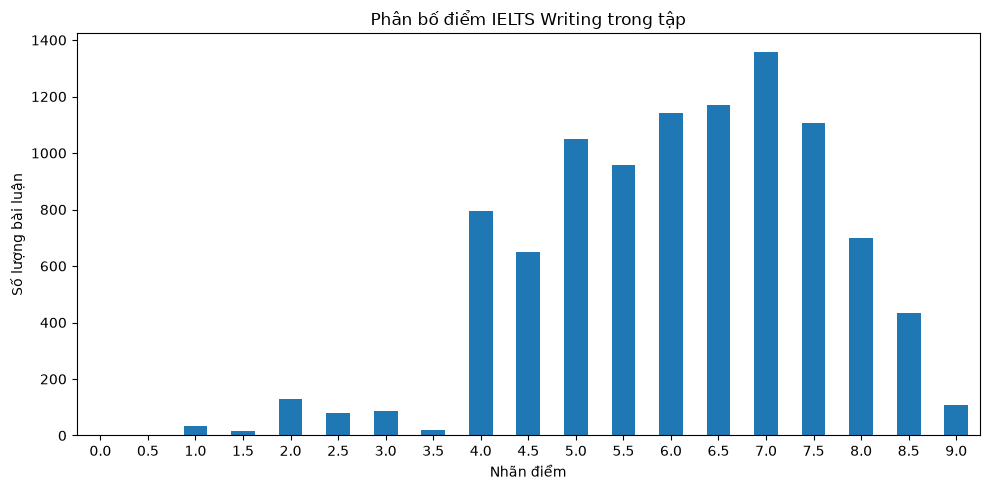

In [16]:
# Phân bố điểm sau khi chuẩn hóa và tính các nhãn <4
def draw_plot(data):
    band_counts = data["band_clean"].value_counts()

    # Sắp xếp nhãn theo thứ tự điểm
    band_order = ["0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5", "4", "4.5", "5", "5.5",
                "6", "6.5", "7", "7.5", "8", "8.5", "9"]
    band_order = [float(x) for x in band_order]
    band_counts = band_counts.reindex(band_order, fill_value=0)

    print("Bảng phân bố điểm:")
    display(band_counts.to_frame("Số lượng"))

    plt.figure(figsize=(10, 5))
    band_counts.plot(kind="bar")
    plt.title(f"Phân bố điểm IELTS Writing trong tập")
    plt.xlabel("Nhãn điểm")
    plt.ylabel("Số lượng bài luận")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
draw_plot(all_data_eda)

In [17]:
all_data_eda['band_clean'].describe()


count    9826.000000
mean        6.098616
std         1.481109
min         0.500000
25%         5.000000
50%         6.000000
75%         7.000000
max         9.000000
Name: band_clean, dtype: float64

In [18]:
import numpy as np
import pandas as pd
import torch
import transformers
# from sentence_transformers import SentenceTransformer
from sentence_transformers import SentenceTransformer
from sklearn.cluster import AgglomerativeClustering
def cluster_prompts_semantic(df, prompt_col='prompt', threshold=0.15):
    """
    Gom cụm đề bài dựa trên ngữ nghĩa bằng SentenceTransformers.
    - threshold càng nhỏ thì gom cụm càng khắt khe (giống nhau hoàn toàn mới cùng cụm).
    """
    print("--- Đang gom cụm đề bài bằng SentenceTransformers ---")
    # Lấy danh sách đề bài duy nhất, loại bỏ giá trị trống
    unique_prompts = df[prompt_col].dropna().unique().tolist()
    
    # 1. Load model Embedding nhẹ và nhanh (hoặc dùng 'all-MiniLM-L6-v2')
    model = SentenceTransformer('all-MiniLM-L6-v2')
    embeddings = model.encode(unique_prompts, show_progress_bar=True)
    
    # 2. Chuẩn hóa vector
    embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
    
    # 3. Gom cụm bằng AgglomerativeClustering (khoảng cách Cosine)
    # distance_threshold=threshold nghĩa là nếu khoảng cách > threshold thì không gộp cụm
    clustering_model = AgglomerativeClustering(
        n_clusters=None, 
        distance_threshold=threshold, 
        metric='cosine', 
        linkage='average'
    )
    clustering_model.fit(embeddings)
    cluster_labels = clustering_model.labels_
    
    # 4. Tạo bản đồ ánh xạ từ Đề bài -> ID cụm
    prompt_to_cluster = dict(zip(unique_prompts, cluster_labels))
    
    # 5. Gán ID cụm vào DataFrame gốc
    df['prompt_cluster_id'] = df[prompt_col].map(prompt_to_cluster)
    
    # Gán giá trị mặc định cho các dòng bị trống đề bài (nếu có)
    df['prompt_cluster_id'] = df['prompt_cluster_id'].fillna(-1).astype(int)
    
    print(f"Đã tạo thành công {df['prompt_cluster_id'].nunique()} cụm đề bài duy nhất!")
    return df

# SỬ DỤNG (Thay 'prompt' bằng tên cột chứa nội dung đề bài của bạn):
all_data_eda = cluster_prompts_semantic(all_data_eda, prompt_col='prompt')


e:\Report\NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Đang gom cụm đề bài bằng SentenceTransformers ---


Batches: 100%|██████████| 109/109 [00:04<00:00, 25.69it/s]


Đã tạo thành công 303 cụm đề bài duy nhất!


In [19]:
all_data_eda

,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean,word_count,prompt_cluster_id
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,Task Achievement: 7\nThe essay effectively add...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,7.5,Interviews form the basic criteria for most la...,357,21
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,Task Achievement: 5.0\n- The candidate has eff...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.0,Interviews form the basic selecting criteria f...,308,21
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,Task Achievement:\n- The candidate has effecti...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interview form the basic selection criteria fo...,401,21
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,Task Achievement:\n- The candidate has adequat...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interviews form the basic selection criteria f...,358,21
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,Task Achievement:\n\nThe essay adequately addr...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,4.0,Interviews from the basic selecting criteria f...,215,21
...,...,...,...,...,...,...,...,...,...,...
9828,9828,Nations should spend more money on skills and ...,"These days, many countries use a huge amount o...",Task Achievement:\nThe essay addresses the tas...,8,train,8.0,Nations should spend more money on skills and ...,308,166
9829,9829,Nations should spend more money on skills and ...,Skills are required in order to achieve succes...,Task Achievement:\n- The candidate has not eff...,<4,train,4.0,Nations should spend more money on skills and ...,240,166
9830,9830,Nations should spend more money on skills and ...,There is a contradictory view among the people...,Task Achievement:\n- The essay adequately addr...,7,train,7.0,Nations should spend more money on skills and ...,261,166
9831,9831,Nations should spend more money on skills and ...,Many today feel that countries should prioriti...,Task Achievement:\n- The candidate has effecti...,7.5,train,7.5,Nations should spend more money on skills and ...,308,166


In [ ]:
#Chỉ có thể hạn chế, không thể ngăn hoànn toàn leakage

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

def split_by_prompt_id(df, test_size=0.15, val_size=0.15, random_state=42):
    """
    Chia dataset Train/Val/Test đảm bảo không có đề bài nào bị rò rỉ chéo.
    """
    print(f"Tổng số bài Essay: {len(df)}")
    print(f"Tổng số Đề bài duy nhất: {df['prompt_cluster_id'].nunique()}")
    
    # --- 1. Tách tập Frozen Test (15%) ---
    gss_test = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    # Lệnh next() lấy ra cụm index của tập Train_Val và tập Test
    train_val_idx, test_idx = next(gss_test.split(df, groups=df['prompt_cluster_id']))
    
    train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
    test_frozen_df = df.iloc[test_idx].reset_index(drop=True)
    
    # --- 2. Tách tập Validation (15% trên tổng số) từ tập Train_Val ---
    # Tính lại tỷ lệ chia: 0.15 / (1 - 0.15) = ~0.176
    val_ratio = val_size / (1.0 - test_size)
    gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=random_state)
    
    train_idx, val_idx = next(gss_val.split(train_val_df, groups=train_val_df['prompt_cluster_id']))
    
    train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
    val_df = train_val_df.iloc[val_idx].reset_index(drop=True)
    
    # --- 3. Báo cáo kết quả kiểm tra Rò rỉ (Leakage Check) ---
    train_prompts = set(train_df['prompt_cluster_id'].unique())
    val_prompts = set(val_df['prompt_cluster_id'].unique())
    test_prompts = set(test_frozen_df['prompt_cluster_id'].unique())
    
    print("\n--- BÁO CÁO PHÂN CHIA ---")
    print(f"Train: {len(train_df)} bài | {len(train_prompts)} đề bài")
    print(f"Val:   {len(val_df)} bài | {len(val_prompts)} đề bài")
    print(f"Test:  {len(test_frozen_df)} bài | {len(test_prompts)} đề bài")
    
    # Kiểm tra giao tập (Intersection) - Nếu ra tập rỗng (set()) là thành công
    overlap_train_test = train_prompts.intersection(test_prompts)
    assert len(overlap_train_test) == 0, f"LỖI RÒ RỈ: Có {len(overlap_train_test)} đề bài bị trùng giữa Train và Test!"

    return train_df, val_df, test_frozen_df

train, val, test = split_by_prompt_id(all_data_eda)



Tổng số bài Essay: 9826
Tổng số Đề bài duy nhất: 303

--- BÁO CÁO PHÂN CHIA ---
Train: 6990 bài | 211 đề bài
Val:   1180 bài | 46 đề bài
Test:  1656 bài | 46 đề bài


In [21]:
train.to_csv(f'{PROCESSED}/train.csv')
test.to_csv(f'{PROCESSED}/test.csv')
val.to_csv(f'{PROCESSED}/val.csv')